# Coffee Sales EDA — Team15

**Decision-maker:** the operator responsible for coffee vending-machine ingredients and machine checks.

**Question:** how should recent drink demand influence ingredient priorities, and when does a decline justify an operational check?

This notebook uses Pandas and Matplotlib to inspect the data before choosing a deliberately small dashboard. The dataset is an author-reported real vending-machine transaction export from [Coffee Sales](https://www.kaggle.com/datasets/ihelon/coffee-sales), not an independently audited ledger. Both supplied files are kept in one prepared CSV without card identifiers, with explicit source tags. The dashboard analyzes one source at a time and defaults to the primary source. Amounts remain in **unverified source units**.


In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dashboard import load_data, default_period, filter_period, headline_metrics, daily_counts, weekly_check

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.labelsize': 11})
all_data = load_data()
data = all_data.loc[all_data.source.eq('index_1')].copy()
secondary = all_data.loc[all_data.source.eq('index_2')].copy()
audit = json.loads(Path('data/source_audit.json').read_text())
display(pd.DataFrame({'rows': [len(data)], 'columns': [len(data.columns)],
                      'start': [data.date.min()], 'end': [data.date.max()]}))
display(pd.DataFrame({'dtype': data.dtypes.astype(str), 'missing': data.isna().sum(),
                      'unique': data.nunique()}))
display(data.head())


,rows,columns,start,end
0,3636,6,2024-03-01,2025-03-23


,dtype,missing,unique
date,datetime64[us],0,381
datetime,datetime64[us],0,3636
cash_type,str,0,2
money,float64,0,20
coffee_name,str,0,8
source,str,0,1


,date,datetime,cash_type,money,coffee_name,source
0,2024-03-01,2024-03-01 10:15:50.520,card,38.7,Latte,index_1
1,2024-03-01,2024-03-01 12:19:22.539,card,38.7,Hot Chocolate,index_1
2,2024-03-01,2024-03-01 12:20:18.089,card,38.7,Hot Chocolate,index_1
3,2024-03-01,2024-03-01 13:46:33.006,card,28.9,Americano,index_1
4,2024-03-01,2024-03-01 13:48:14.626,card,38.7,Latte,index_1


## 1. Compare the supplied transaction streams

The table below is a saved audit of the two supplied originals, produced by `scripts/prepare_data.py`. Re-run preparation with the originals to reproduce its hashes and counts. Both sources' transaction fields are included in the small published CSV with provenance. Date overlap plus different product lists does not establish one common machine or business scope. We do not aggregate them into one trend or infer an unverified scope change as growth.


In [2]:
source_comparison = pd.DataFrame(audit['source_audits'])
display(source_comparison[['filename', 'bytes', 'rows', 'date_min', 'date_max',
                           'drink_categories', 'duplicates_all_fields', 'sales_source_units']])
print('Normalized matches between the two supplied files:', audit['normalized_cross_file_matches'])
print('Published CSV size:', audit['published_csv_bytes'], 'bytes')
display(pd.DataFrame(audit['source_audits'][0]['missing'].items(), columns=['original field', 'missing values']))
display(secondary.head())
print('Secondary recorded rows:', len(secondary), 'sales:', secondary.money.sum())
display(secondary[secondary.duplicated(keep=False)])


,filename,bytes,rows,date_min,date_max,drink_categories,duplicates_all_fields,sales_source_units
0,index_1.csv,279369,3636,2024-03-01,2025-03-23,8,0,115431.58
1,index_2.csv,14962,262,2025-02-08,2025-03-23,30,2,6890.00


Normalized matches between the two supplied files: 0
Published CSV size: 254446 bytes


,original field,missing values
0,date,0
1,datetime,0
2,cash_type,0
3,card,89
4,money,0
5,coffee_name,0


,date,datetime,cash_type,money,coffee_name,source
3007,2025-02-08,2025-02-08 14:26:04,cash,15.0,Tea,index_2
3008,2025-02-08,2025-02-08 14:28:26,cash,15.0,Tea,index_2
3009,2025-02-08,2025-02-08 14:33:04,card,20.0,Espresso,index_2
3012,2025-02-08,2025-02-08 15:51:04,card,30.0,Chocolate with coffee,index_2
3013,2025-02-08,2025-02-08 16:35:01,cash,27.0,Chocolate with milk,index_2


Secondary recorded rows: 262 sales: 6890.0


,date,datetime,cash_type,money,coffee_name,source
3374,2025-02-26,2025-02-26 09:41:12,cash,25.0,Americano with milk,index_2
3375,2025-02-26,2025-02-26 09:41:12,cash,25.0,Americano with milk,index_2
3886,2025-03-23,2025-03-23 10:25:48,cash,25.0,Americano with milk,index_2
3887,2025-03-23,2025-03-23 10:25:48,cash,25.0,Americano with milk,index_2


## 2. Completeness and reconciliation

The 89 absent card values in the original primary file all belong to cash payments. They are a payment-channel characteristic, not a reason to delete transactions. The published file omits the entire card identifier column. Required fields are complete, amounts are positive and dates agree with timestamps.

No-record dates are ambiguous: closure, genuine zero sales or incomplete capture could all produce them. We do not invent transactions or substitute zeros. The last date has no end-of-day completeness marker. Secondary-source duplicate rows are retained: timestamps are only precise to the second, and no transaction ID establishes whether these are distinct sales or duplicate exports. The dashboard flags them within the selected range.


In [3]:
assert len(data) == 3636
assert 'card' not in data
assert data.isna().sum().sum() == 0
assert (data.money > 0).all()
assert data.date.eq(data.datetime.dt.normalize()).all()
assert not data.duplicated().any()
assert data.cash_type.eq('cash').sum() == 89
metrics = headline_metrics(data)
assert round(metrics['sales'], 2) == 115431.58
display(pd.Series(metrics, name='full-period reconciliation'))
missing_dates = pd.date_range(data.date.min(), data.date.max()).difference(pd.DatetimeIndex(data.date.unique()))
display(pd.DataFrame({'dates without records': missing_dates}))
display(data.money.describe())


sales           115431.580000
transactions      3636.000000
average             31.746859
Name: full-period reconciliation, dtype: float64

,dates without records
0,2024-05-01
1,2024-05-04
2,2024-05-05
3,2024-11-27
4,2025-01-01
5,2025-01-19
6,2025-01-23


count    3636.000000
mean       31.746859
std         4.919926
min        18.120000
25%        27.920000
50%        32.820000
75%        35.760000
max        40.000000
Name: money, dtype: float64

## 3. Distributions: transaction value and product demand

A value histogram is useful for checking unusual amounts but does not deserve a permanent chart on an ingredient-planning dashboard. The product count distribution directly informs the chosen business decision.


,transactions,sales,average_transaction,price_values
coffee_name,,,,
Americano with Milk,824,25269.12,30.67,6
Latte,782,27866.30,35.63,6
Americano,578,15062.26,26.06,6
Cappuccino,501,18034.14,36.00,6
Cortado,292,7534.86,25.80,5
Hot Chocolate,282,10172.46,36.07,6
Cocoa,243,8678.16,35.71,6
Espresso,134,2814.28,21.00,5


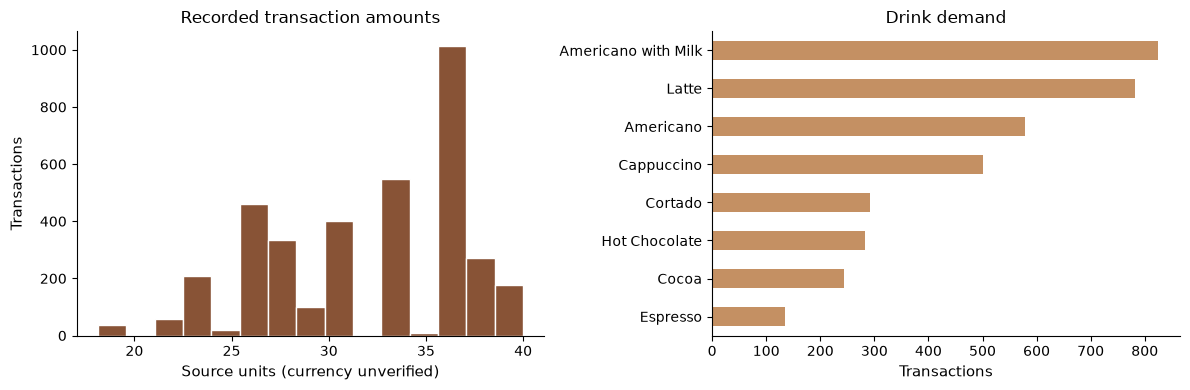

In [4]:
products = data.groupby('coffee_name').agg(transactions=('money', 'size'),
    sales=('money', 'sum'), average_transaction=('money', 'mean'), price_values=('money', 'nunique'))
products = products.sort_values('transactions', ascending=False)
display(products.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(data.money, bins=15, color='#885336', edgecolor='white')
axes[0].set(title='Recorded transaction amounts', xlabel='Source units (currency unverified)', ylabel='Transactions')
products.transactions.sort_values().plot.barh(ax=axes[1], color='#C49063')
axes[1].set(title='Drink demand', xlabel='Transactions', ylabel='')
fig.tight_layout()
plt.show()


## 4. Time patterns and period selection

The default dashboard period is February 2025, the most recent fully elapsed month in the snapshot. March stops on the 23rd and should not be compared to a complete month as if coverage were equal. Even the last fully elapsed month must be checked for no-record dates.


sales           13215.48000
transactions      423.00000
average            31.24227
Name: default period: 2025-02-01 to 2025-02-28, dtype: float64

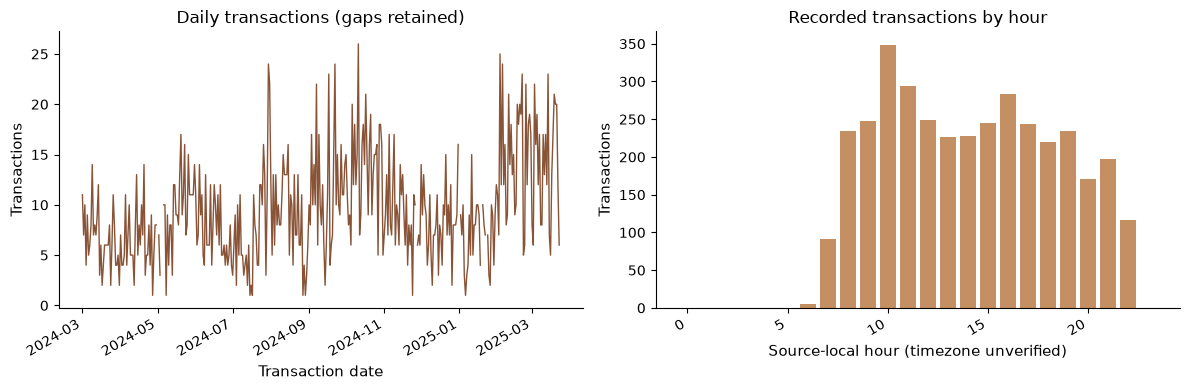

In [5]:
start, end = default_period(data)
selected = filter_period(data, start, end)
display(pd.Series(headline_metrics(selected), name=f'default period: {start} to {end}'))
daily = daily_counts(data, data.date.min(), data.date.max())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(daily.date, daily.transactions, color='#885336', linewidth=1)
axes[0].set(title='Daily transactions (gaps retained)', xlabel='Transaction date', ylabel='Transactions')
hourly = data.groupby(data.datetime.dt.hour).size().reindex(range(24), fill_value=0)
axes[1].bar(hourly.index, hourly.values, color='#C49063')
axes[1].set(title='Recorded transactions by hour', xlabel='Source-local hour (timezone unverified)', ylabel='Transactions')
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
plt.show()


**Interpretation:** hourly patterns are interesting, but operating hours and staffing requirements are absent. We retain the daily trend for demand investigations and omit an extra hourly chart. This avoids turning every EDA finding into a dashboard element.

## 5. Relationships: product mix, pricing and sales

Revenue combines transaction volume and amount per transaction. Drink types have different prices, and each drink has multiple recorded amounts. Higher revenue therefore does not automatically mean more transactions or more ingredient demand. We use transaction ranking for planning priorities and keep sales plus average transaction amount as contextual headline numbers.


,transactions,sales,average_transaction
month,,,
2024-03,206,7050.20,34.22
2024-04,196,6720.56,34.29
2024-05,267,9063.42,33.95
2024-06,227,7758.76,34.18
2024-07,237,6915.94,29.18
2024-08,272,7613.84,27.99
2024-09,344,9988.64,29.04
2024-10,426,13891.16,32.61
2024-11,259,8590.54,33.17


,transactions,sales,average_transaction,price_values
coffee_name,,,,
Americano with Milk,824,25269.12,30.67,6
Latte,782,27866.30,35.63,6
Americano,578,15062.26,26.06,6
Cappuccino,501,18034.14,36.00,6
Cortado,292,7534.86,25.80,5
Hot Chocolate,282,10172.46,36.07,6
Cocoa,243,8678.16,35.71,6
Espresso,134,2814.28,21.00,5


Largest transaction count: Americano with Milk
Largest recorded sales: Latte


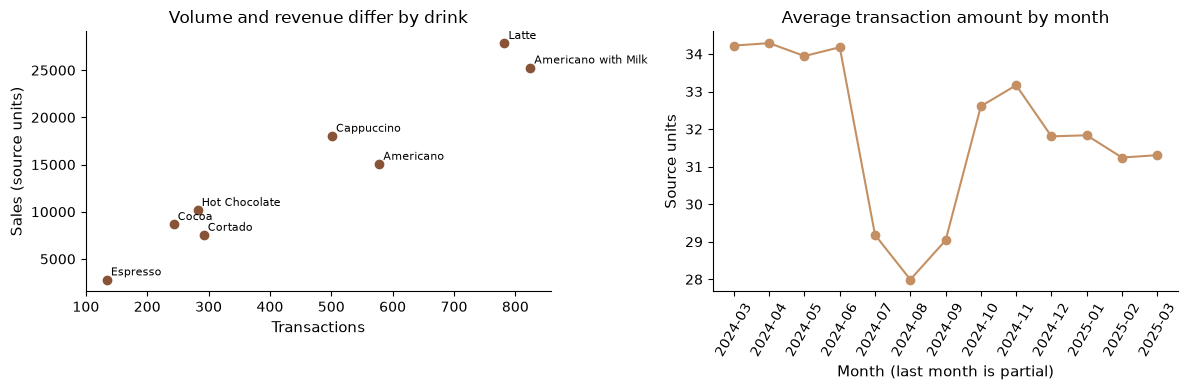

In [6]:
monthly = data.assign(month=data.date.dt.to_period('M').astype(str)).groupby('month').agg(
    transactions=('money', 'size'), sales=('money', 'sum'), average_transaction=('money', 'mean'))
display(monthly.round(2))
display(products[['transactions', 'sales', 'average_transaction', 'price_values']].round(2))
print('Largest transaction count:', products.transactions.idxmax())
print('Largest recorded sales:', products.sales.idxmax())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(products.transactions, products.sales, color='#885336')
for name, row in products.iterrows():
    axes[0].annotate(name, (row.transactions, row.sales), fontsize=8, xytext=(3, 3), textcoords='offset points')
axes[0].set(title='Volume and revenue differ by drink', xlabel='Transactions', ylabel='Sales (source units)')
axes[1].plot(monthly.index, monthly.average_transaction, marker='o', color='#C49063')
axes[1].tick_params(axis='x', rotation=60)
axes[1].set(title='Average transaction amount by month', xlabel='Month (last month is partial)', ylabel='Source units')
fig.tight_layout()
plt.show()


## 6. One proposed operational check

Compare recorded transactions in two consecutive seven-day windows. A decline of at least 20% prompts a data and machine review, not a causal diagnosis. This illustrative threshold is not calibrated to actual fault or stockout events: the data contains neither label. Suppress the comparison if either window has a no-record date or falls outside the selected range. Exclude the latest source date, whose full-day coverage is unverified.


In [7]:
check = weekly_check(data, start, end, data.date.max())
display(pd.Series(check, name='default-period seven-day check'))
assert check['current'] == 99 and check['previous'] == 119
assert check['status'] == 'within_threshold'
assert weekly_check(data, '2024-04-20', '2024-05-06', data.date.max())['status'] == 'unavailable'

history = []
for cutoff in pd.date_range(data.date.min() + pd.Timedelta(days=13), data.date.max() - pd.Timedelta(days=1)):
    result = weekly_check(data, data.date.min(), cutoff, data.date.max())
    history.append({'end': cutoff, 'status': result['status'], 'change': result.get('change')})
history = pd.DataFrame(history)
display(history.status.value_counts().rename('comparison dates'))
display(history.loc[history.status.eq('review')].head())


cutoff            2025-02-28 00:00:00
current_start     2025-02-22 00:00:00
previous_start    2025-02-15 00:00:00
previous_end      2025-02-21 00:00:00
status               within_threshold
current                            99
previous                          119
change                      -0.168067
Name: default-period seven-day check, dtype: object

status
within_threshold    240
review               70
unavailable          64
Name: comparison dates, dtype: int64

,end,status,change
4,2024-03-18,review,-0.245614
5,2024-03-19,review,-0.236364
6,2024-03-20,review,-0.338983
7,2024-03-21,review,-0.492308
8,2024-03-22,review,-0.400000


**Interpretation:** the default check is 99 versus 119 transactions, a 16.8% decline. It does not cross the proposed threshold, but that is not evidence that the machine is healthy. Counts of historical threshold crossings show how often the proposal would prompt review, not its precision or business value. These would require verified operating incidents.

## 7. Final design decision

**Three KPIs:** sales in source units, recorded transactions, and average transaction amount. All follow the date filter.

**Two charts:** daily recorded transactions and the top eight drinks by transaction count. Show calendar gaps, state any categories outside the top-eight chart, and do not imply exact inventory or profit calculations. Headline totals include all drink types.

**Two filters:** source export and inclusive transaction dates. No verified machine/location key exists, so the source selector is labelled as provenance, not as machine identity. Switching source changes the coverage limits and default dates.

**Omitted:** payment pie, anonymous customer leaderboard, hourly chart, raw transaction table, stockout and profit metrics. These either do not change this operator's chosen action or cannot be computed reliably.

**Order:** title/persona → period → KPIs → qualified check → two explanatory charts → data-period/refresh footer → collapsed limitations.

**Production cadence:** nightly transaction ingestion; daily exception review; weekly ingredient prioritization. The delivered demo is a frozen snapshot with no live refresh.

**Sources and reproducibility:** [Kaggle dataset](https://www.kaggle.com/datasets/ihelon/coffee-sales), [author introduction](https://www.kaggle.com/getting-started/521180), prepared CSV and saved source audit. README answers the assignment's Steps 1–4 in detail. No actual operator interviews, incident labels or savings estimates are claimed.
